#Problem 1: Load and inspect the dataset

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv("/content/Lab4.csv")
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [3]:
print(df.tail())

     PassengerId  Survived  Pclass                                      Name  \
886          887         0       2                     Montvila, Rev. Juozas   
887          888         1       1              Graham, Miss. Margaret Edith   
888          889         0       3  Johnston, Miss. Catherine Helen "Carrie"   
889          890         1       1                     Behr, Mr. Karl Howell   
890          891         0       3                       Dooley, Mr. Patrick   

        Sex   Age  SibSp  Parch      Ticket   Fare Cabin Embarked  
886    male  27.0      0      0      211536  13.00   NaN        S  
887  female  19.0      0      0      112053  30.00   B42        S  
888  female   NaN      1      2  W./C. 6607  23.45   NaN        S  
889    male  26.0      0      0      111369  30.00  C148        C  
890    male  32.0      0      0      370376   7.75   NaN        Q  


In [4]:
print("Shape:", df.shape)
df.info()

Shape: (891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
numerical = df.select_dtypes(include="number").columns.tolist()
categorical = df.select_dtypes(exclude="number").columns.tolist()
print("Numerical columns:", numerical)
print("Categorical columns:", categorical)

Numerical columns: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


#Problem 2: Line plot of average fare by passenger class

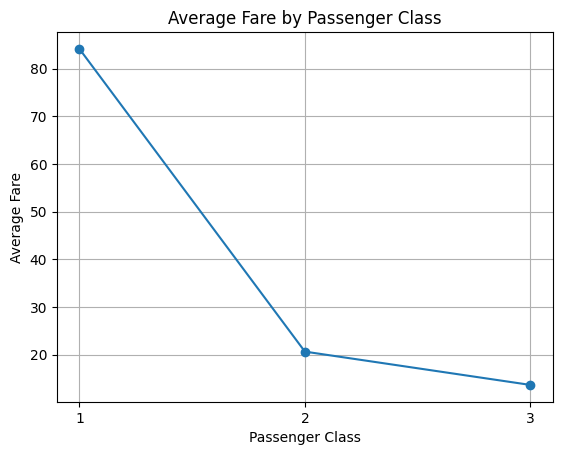

In [6]:
avg_fare = df.groupby("Pclass")["Fare"].mean()

plt.plot(avg_fare.index, avg_fare.values, marker="o")
plt.title("Average Fare by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Average Fare")
plt.xticks([1, 2, 3])
plt.grid(True)
plt.show()

#Problem 3:ScatterPlot(Passenger Age vs Fare)

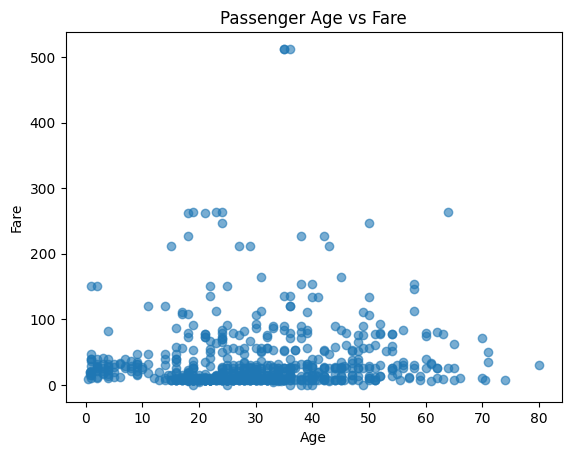

In [7]:
plt.scatter(df["Age"], df["Fare"], alpha=0.6)
plt.title("Passenger Age vs Fare")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.show()

#Problrm 4: BarChart to compare the number of male and female passengers

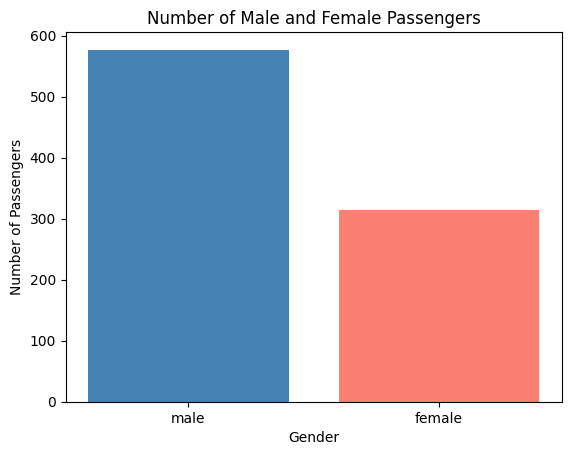

In [9]:
gender_counts = df["Sex"].value_counts()

plt.bar(gender_counts.index, gender_counts.values, color=["steelblue", "salmon"])
plt.title("Number of Male and Female Passengers")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.show()

#Problrm 5: Histogram of passenger Ages

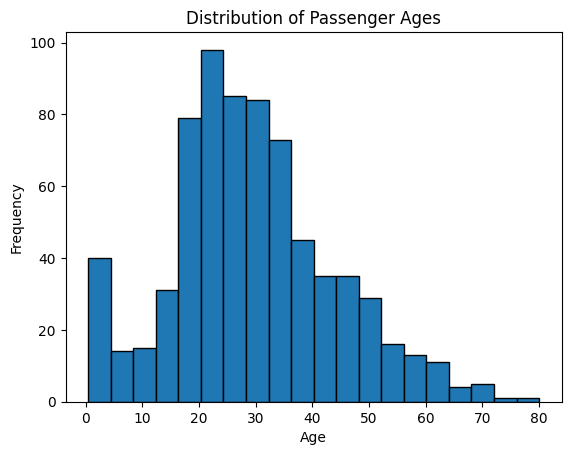

In [10]:
plt.hist(df["Age"].dropna(), bins=20, edgecolor="black")
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

# Problem 6: Pie chart of survival

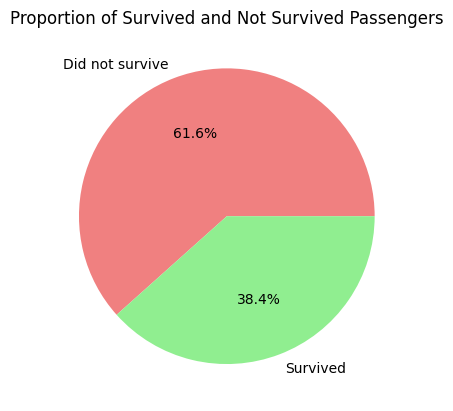

In [12]:
survival_counts = df["Survived"].value_counts().sort_index()

plt.pie(survival_counts.values,
        labels=["Did not survive", "Survived"],
        autopct="%1.1f%%",
        colors=["lightcoral", "lightgreen"])
plt.title("Proportion of Survived and Not Survived Passengers")
plt.show()

#Problem 7: Two subplots (age histogram and class bar chart)

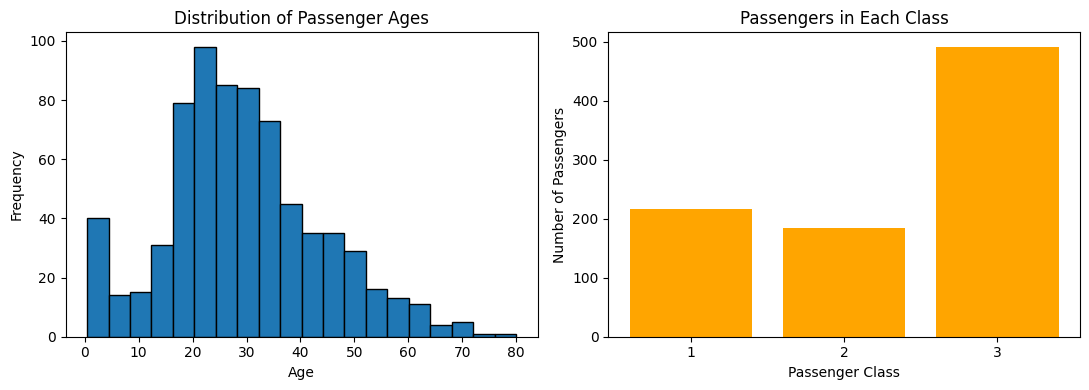

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Histogram of age
ax[0].hist(df["Age"].dropna(), bins=20, edgecolor="black")
ax[0].set_title("Distribution of Passenger Ages")
ax[0].set_xlabel("Age")
ax[0].set_ylabel("Frequency")

# Bar chart of class
class_counts = df["Pclass"].value_counts().sort_index()
ax[1].bar(class_counts.index.astype(str), class_counts.values, color="orange")
ax[1].set_title("Passengers in Each Class")
ax[1].set_xlabel("Passenger Class")
ax[1].set_ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

# Problem 8: Three subplots (gender, fare, survival)

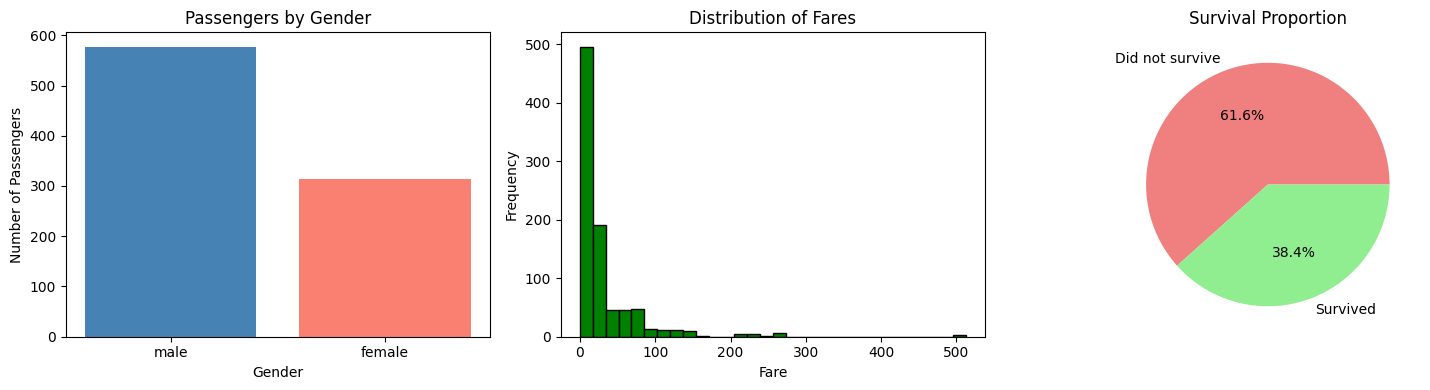

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Bar chart: gender
ax[0].bar(gender_counts.index, gender_counts.values, color=["steelblue", "salmon"])
ax[0].set_title("Passengers by Gender")
ax[0].set_xlabel("Gender")
ax[0].set_ylabel("Number of Passengers")

# Histogram: fare
ax[1].hist(df["Fare"], bins=30, edgecolor="black", color="green")
ax[1].set_title("Distribution of Fares")
ax[1].set_xlabel("Fare")
ax[1].set_ylabel("Frequency")

# Pie chart: survival
ax[2].pie(survival_counts.values,
          labels=["Did not survive", "Survived"],
          autopct="%1.1f%%",
          colors=["lightcoral", "lightgreen"])
ax[2].set_title("Survival Proportion")

plt.tight_layout()
plt.show()